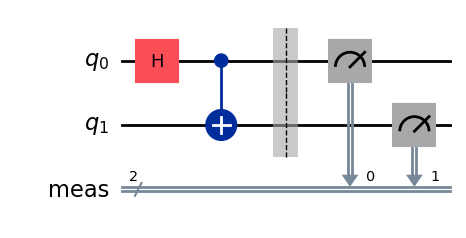

In [1]:
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error

# Build your standard Bell Circuit
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

# Define custom quantum errors
p_error = 0.05  # 5% chance of an error occurring
# simulate the bit flip error
error_gate1 = pauli_error([('X', p_error), ('I', 1 - p_error)])
# tensor the errors together to cover both qubits - necessary for 2 qubits error
error_gate2 = error_gate1.tensor(error_gate1)

# Create the Noise Model and assign errors to specific gates
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(error_gate1, ["h"])   # Apply to H gate
noise_model.add_all_qubit_quantum_error(error_gate2, ["cx"])  # Apply to CNOT gate


qc.draw(output="mpl")

Noisy Measurement Counts: {'01': 47, '10': 45, '00': 451, '11': 481}


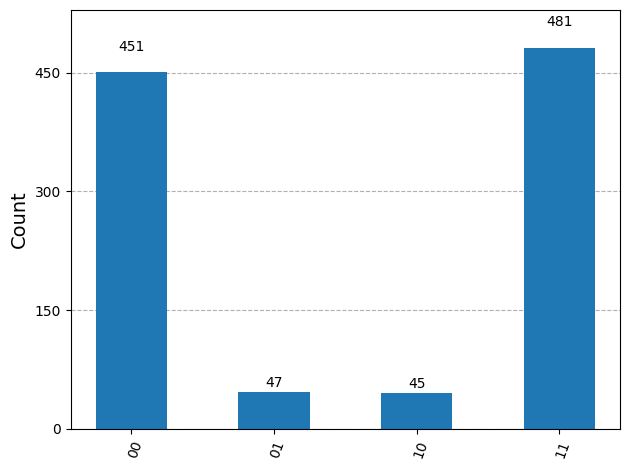

In [2]:

backend = AerSimulator(noise_model=noise_model)
pm = generate_preset_pass_manager(backend=backend, optimization_level=1) # Transpile the circuit to the simulator's basis gates
isa_circuit = pm.run(qc)

# Run the noisy simulation
job = backend.run(isa_circuit, shots=1024)
noisy_counts = job.result().get_counts()

print("Noisy Measurement Counts:", noisy_counts)
plot_histogram(noisy_counts)